# Visualização de Resultados Modal - Regressão Linear (r²)

Notebook para gerar plots dos resultados da análise de regressão linear (experimento 03), espelhando a estrutura do notebook PREDEP para comparação direta.

In [8]:
import sys
from pathlib import Path
import xarray as xr
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from matplotlib.gridspec import GridSpec

sys.path.insert(0, str(Path.cwd().parent))

## 1. Carregar Resultados Modal

In [9]:
results_dir = Path("../results/regression/TNA")

nc_files = list(results_dir.glob("*.nc"))
print(f"Arquivos encontrados: {len(nc_files)}")
for f in nc_files:
    print(f"  - {f.name}")

Arquivos encontrados: 4
  - TNA_DJF_regression_brazil.nc
  - TNA_MAM_regression_brazil.nc
  - TNA_JJA_regression_brazil.nc
  - TNA_SON_regression_brazil.nc


## 2. Carregar e Combinar Dados

In [10]:
seasons = ["DJF", "MAM", "JJA", "SON"]
mov_index = "TNA"

all_data = []
for season in seasons:
    nc_file = results_dir / f"{mov_index}_{season}_regression_brazil.nc"

    if nc_file.exists():
        ds = xr.open_dataset(nc_file)
        print(f"✓ {season}: {ds.dims}")

        n_lags = len(ds.lag)
        r2_list = []
        for lag in range(n_lags):
            r2_data = ds[f'r2_lag{lag}'].values
            r2_list.append(r2_data)

        r2_stacked = np.stack(r2_list, axis=0)
        all_data.append(r2_stacked)

        if len(all_data) == 1:
            lats = ds.latitude.values
            lons = ds.longitude.values
    else:
        print(f"⚠️  {season}: arquivo não encontrado")

print(f"\nEstações carregadas: {len(all_data)}")

✓ DJF: Frozen({'latitude': 393, 'longitude': 391, 'lag': 12})
✓ MAM: Frozen({'latitude': 393, 'longitude': 391, 'lag': 12})
✓ JJA: Frozen({'latitude': 393, 'longitude': 391, 'lag': 12})
✓ SON: Frozen({'latitude': 393, 'longitude': 391, 'lag': 12})

Estações carregadas: 4


## 3. Criar Dataset Combinado

In [11]:
combined_r2 = np.stack(all_data, axis=0)[np.newaxis, :, :, :, :]

print(f"Shape combinado: {combined_r2.shape}")
print(f"  mov=1, seasons={len(all_data)}, lags={n_lags}, lat={len(lats)}, lon={len(lons)}")

ds_combined = xr.Dataset(
    {'regression_r2': (['mov', 'season', 'lag', 'latitude', 'longitude'], combined_r2)},
    coords={
        'mov': [mov_index],
        'season': seasons[:len(all_data)],
        'lag': list(range(n_lags)),
        'latitude': lats,
        'longitude': lons
    }
)

print(f"\nDataset criado:")
print(ds_combined)

Shape combinado: (1, 4, 12, 393, 391)
  mov=1, seasons=4, lags=12, lat=393, lon=391

Dataset criado:
<xarray.Dataset>
Dimensions:        (mov: 1, season: 4, lag: 12, latitude: 393, longitude: 391)
Coordinates:
  * mov            (mov) <U3 'TNA'
  * season         (season) <U3 'DJF' 'MAM' 'JJA' 'SON'
  * lag            (lag) int64 0 1 2 3 4 5 6 7 8 9 10 11
  * latitude       (latitude) float32 -33.85 -33.75 -33.65 ... 5.15 5.25 5.35
  * longitude      (longitude) float32 -73.85 -73.75 -73.65 ... -34.95 -34.85
Data variables:
    regression_r2  (mov, season, lag, latitude, longitude) float64 nan ... nan


## 4. Funções de Plot

In [12]:
def plot_4x4_optimal_lags_r2(ds, mov_index, output_dir, seasons=['DJF', 'MAM', 'JJA', 'SON']):
    """Plot 4x4: r² máximo + 3 maiores lags."""
    valid_seasons = []
    for season_idx, season in enumerate(seasons):
        r2_data = ds['regression_r2'].isel(mov=0, season=season_idx)
        if not np.all(np.isnan(r2_data.values)):
            valid_seasons.append((season_idx, season))

    if not valid_seasons:
        print("   ⚠️  Nenhuma estação com dados válidos")
        return None

    n_cols = len(valid_seasons)
    fig = plt.figure(figsize=(5 * n_cols, 22))
    gs = GridSpec(4, n_cols + 1, figure=fig,
                  width_ratios=[1] * n_cols + [0.05],
                  hspace=0.25, wspace=0.15,
                  left=0.05, right=0.95, top=0.94, bottom=0.05)
    plt.rcParams['text.usetex'] = False

    levels_r2 = np.arange(0.0, 1.1, 0.1)
    norm_r2 = BoundaryNorm(levels_r2, ncolors=plt.cm.jet.N, clip=True)
    lag_boundaries = np.arange(-0.5, 13.5, 1.0)
    lag_norm = BoundaryNorm(lag_boundaries, ncolors=plt.cm.jet.N, clip=True)

    im_r2 = None
    im_lag = None

    for col_idx, (season_idx, season) in enumerate(valid_seasons):
        r2_values = ds['regression_r2'].isel(mov=0, season=season_idx).values

        sorted_indices = np.argsort(np.nan_to_num(r2_values, nan=-999), axis=0)
        lag_1st = sorted_indices[-1, :, :]
        lag_2nd = sorted_indices[-2, :, :]
        lag_3rd = sorted_indices[-3, :, :]

        lat_idx, lon_idx = np.meshgrid(
            np.arange(r2_values.shape[1]),
            np.arange(r2_values.shape[2]),
            indexing='ij'
        )
        r2_max = r2_values[lag_1st, lat_idx, lon_idx]

        all_nan = np.all(np.isnan(r2_values), axis=0)
        r2_max  = np.where(all_nan, np.nan, r2_max)
        lag_1st = np.where(all_nan, np.nan, lag_1st.astype(float))
        lag_2nd = np.where(all_nan, np.nan, lag_2nd.astype(float))
        lag_3rd = np.where(all_nan, np.nan, lag_3rd.astype(float))

        ax1 = fig.add_subplot(gs[0, col_idx])
        im1 = ax1.imshow(r2_max, cmap='jet', norm=norm_r2,
                         aspect='auto', origin='lower', interpolation='nearest')
        ax1.set_title(f'{season} - $r^2$ máximo', fontsize=12, fontweight='bold')
        ax1.axis('off')
        if im_r2 is None:
            im_r2 = im1

        ax2 = fig.add_subplot(gs[1, col_idx])
        im2 = ax2.imshow(lag_1st, cmap='jet', norm=lag_norm,
                         aspect='auto', origin='lower', interpolation='nearest')
        ax2.set_title(f'{season} - Lag $1^{{\\circ}}$', fontsize=12, fontweight='bold')
        ax2.axis('off')
        if im_lag is None:
            im_lag = im2

        ax3 = fig.add_subplot(gs[2, col_idx])
        ax3.imshow(lag_2nd, cmap='jet', norm=lag_norm,
                   aspect='auto', origin='lower', interpolation='nearest')
        ax3.set_title(f'{season} - Lag $2^{{\\circ}}$', fontsize=12, fontweight='bold')
        ax3.axis('off')

        ax4 = fig.add_subplot(gs[3, col_idx])
        ax4.imshow(lag_3rd, cmap='jet', norm=lag_norm,
                   aspect='auto', origin='lower', interpolation='nearest')
        ax4.set_title(f'{season} - Lag $3^{{\\circ}}$', fontsize=12, fontweight='bold')
        ax4.axis('off')

    cbar_ax1 = fig.add_subplot(gs[0, n_cols])
    cbar1 = fig.colorbar(im_r2, cax=cbar_ax1, ticks=np.arange(0.0, 1.1, 0.1))
    cbar1.set_label('$r^2$', fontsize=12, fontweight='bold')

    cbar_ax2 = fig.add_subplot(gs[1:4, n_cols])
    cbar2 = fig.colorbar(im_lag, cax=cbar_ax2, ticks=list(range(13)))
    cbar2.set_label('Lag (meses)', fontsize=12, fontweight='bold')

    plt.suptitle(
        f'Lags Ótimos por Estação (Regressão Linear): {mov_index}\n'
        f'Linha 1: $r^2$ máximo | Linhas 2-4: Lags do $1^{{\\circ}}$, $2^{{\\circ}}$ e $3^{{\\circ}}$ maiores $r^2$',
        fontsize=18, fontweight='bold'
    )

    output_file = output_dir / f"optimal_lag_seasons_{mov_index}_regression.png"
    plt.savefig(output_file, dpi=200, bbox_inches='tight')
    plt.close()
    return output_file


def plot_12x4_all_lags_r2(ds, mov_index, output_dir, seasons=['DJF', 'MAM', 'JJA', 'SON']):
    """Plot 12x4: Todos os lags."""
    valid_seasons = []
    for season_idx, season in enumerate(seasons):
        r2_data = ds['regression_r2'].isel(mov=0, season=season_idx)
        if not np.all(np.isnan(r2_data.values)):
            valid_seasons.append((season_idx, season))

    if not valid_seasons:
        print("   ⚠️  Nenhuma estação com dados válidos")
        return None

    n_cols = len(valid_seasons)
    fig = plt.figure(figsize=(3 * n_cols, 30))
    gs = GridSpec(13, n_cols + 1, figure=fig,
                  width_ratios=[1] * n_cols + [0.05],
                  hspace=0.05, wspace=0.05,
                  left=0.08, right=0.95, top=0.96, bottom=0.02)
    plt.rcParams['text.usetex'] = False

    levels = np.arange(0.0, 1.1, 0.1)
    cmap = plt.cm.jet
    norm = BoundaryNorm(levels, ncolors=cmap.N, clip=True)

    n_lags = ds.dims['lag']
    im = None
    for lag in range(n_lags):
        for col_idx, (season_idx, season) in enumerate(valid_seasons):
            ax = fig.add_subplot(gs[lag, col_idx])
            data = ds['regression_r2'].isel(mov=0, season=season_idx, lag=lag).values
            im = ax.imshow(data, cmap=cmap, norm=norm,
                           aspect='auto', origin='lower', interpolation='nearest')
            ax.axis('off')
            if lag == 0:
                ax.set_title(season, fontsize=11, fontweight='bold', pad=3)
            if col_idx == 0:
                ax.text(-0.15, 0.5, f'Lag {lag}',
                        transform=ax.transAxes,
                        rotation=90, va='center', ha='center',
                        fontsize=10, fontweight='bold')

    cbar_ax = fig.add_subplot(gs[:, n_cols])
    cbar = fig.colorbar(im, cax=cbar_ax, ticks=levels)
    cbar.set_label(
        '$r^2$ (Regressão Linear)\n0=Sem relação, 1=Relação perfeita',
        fontsize=11, fontweight='bold'
    )

    plt.suptitle(
        f'Regressão Linear $r^2$: {mov_index}\n'
        f'Linhas = Lags (0-11 meses) | Colunas = Estações (DJF, MAM, JJA, SON)',
        fontsize=14, fontweight='bold', y=0.99
    )

    output_file = output_dir / f"regression_12x4_grid_{mov_index}.png"
    plt.savefig(output_file, dpi=200, bbox_inches='tight')
    plt.close()
    return output_file


print("Funções de plot carregadas.")

Funções de plot carregadas.


## 5. Gerar Plot 4x4 (Lags Ótimos)

📊 Gerando plot 4x4 (Lags Ótimos)...
✅ Plot salvo: ../results/regression/TNA/plots/optimal_lag_seasons_TNA_MODAL_regression.png


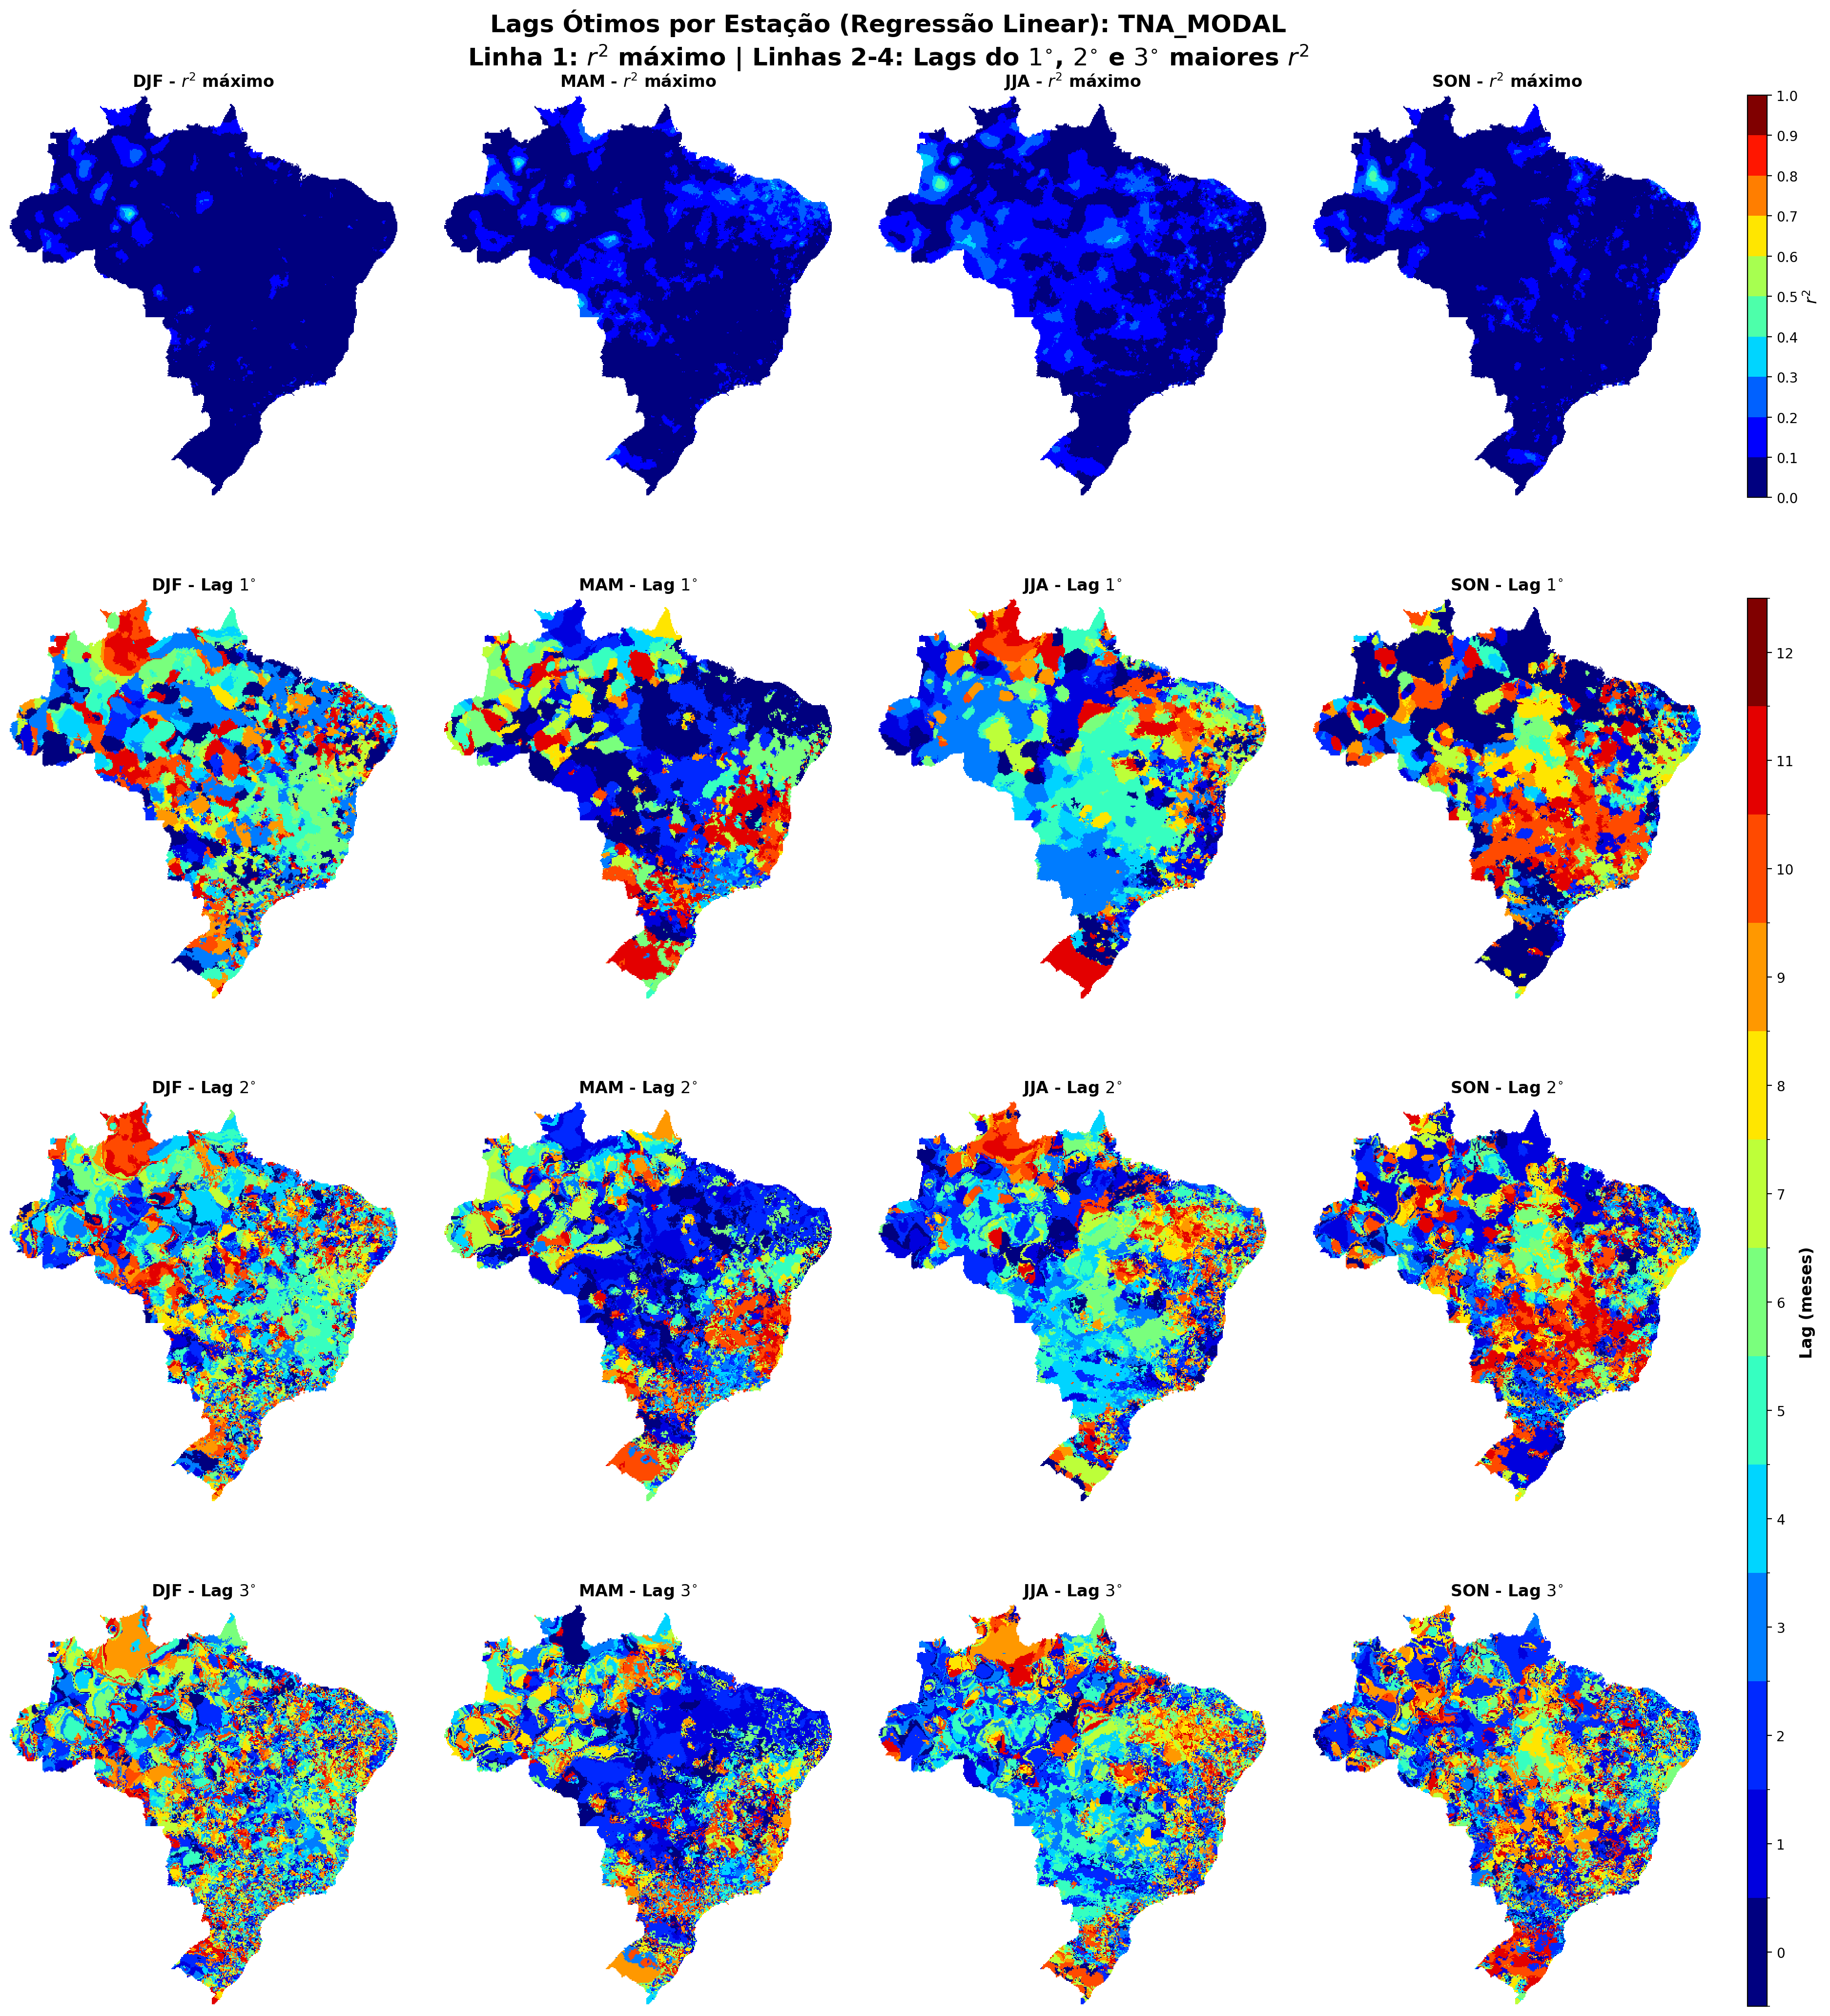

In [13]:
output_dir = results_dir / "plots"
output_dir.mkdir(exist_ok=True)

print("📊 Gerando plot 4x4 (Lags Ótimos)...")
output_4x4 = plot_4x4_optimal_lags_r2(
    ds_combined,
    f'{mov_index}_MODAL',
    output_dir,
    seasons=seasons[:len(all_data)]
)

if output_4x4:
    print(f"✅ Plot salvo: {output_4x4}")
    from IPython.display import Image, display
    display(Image(filename=str(output_4x4)))
else:
    print("⚠️  Erro ao gerar plot 4x4")

## 6. Gerar Plot 12x4 (Todos os Lags)

📊 Gerando plot 12x4 (Todos os Lags)...
✅ Plot salvo: ../results/regression/TNA/plots/regression_12x4_grid_TNA_MODAL.png


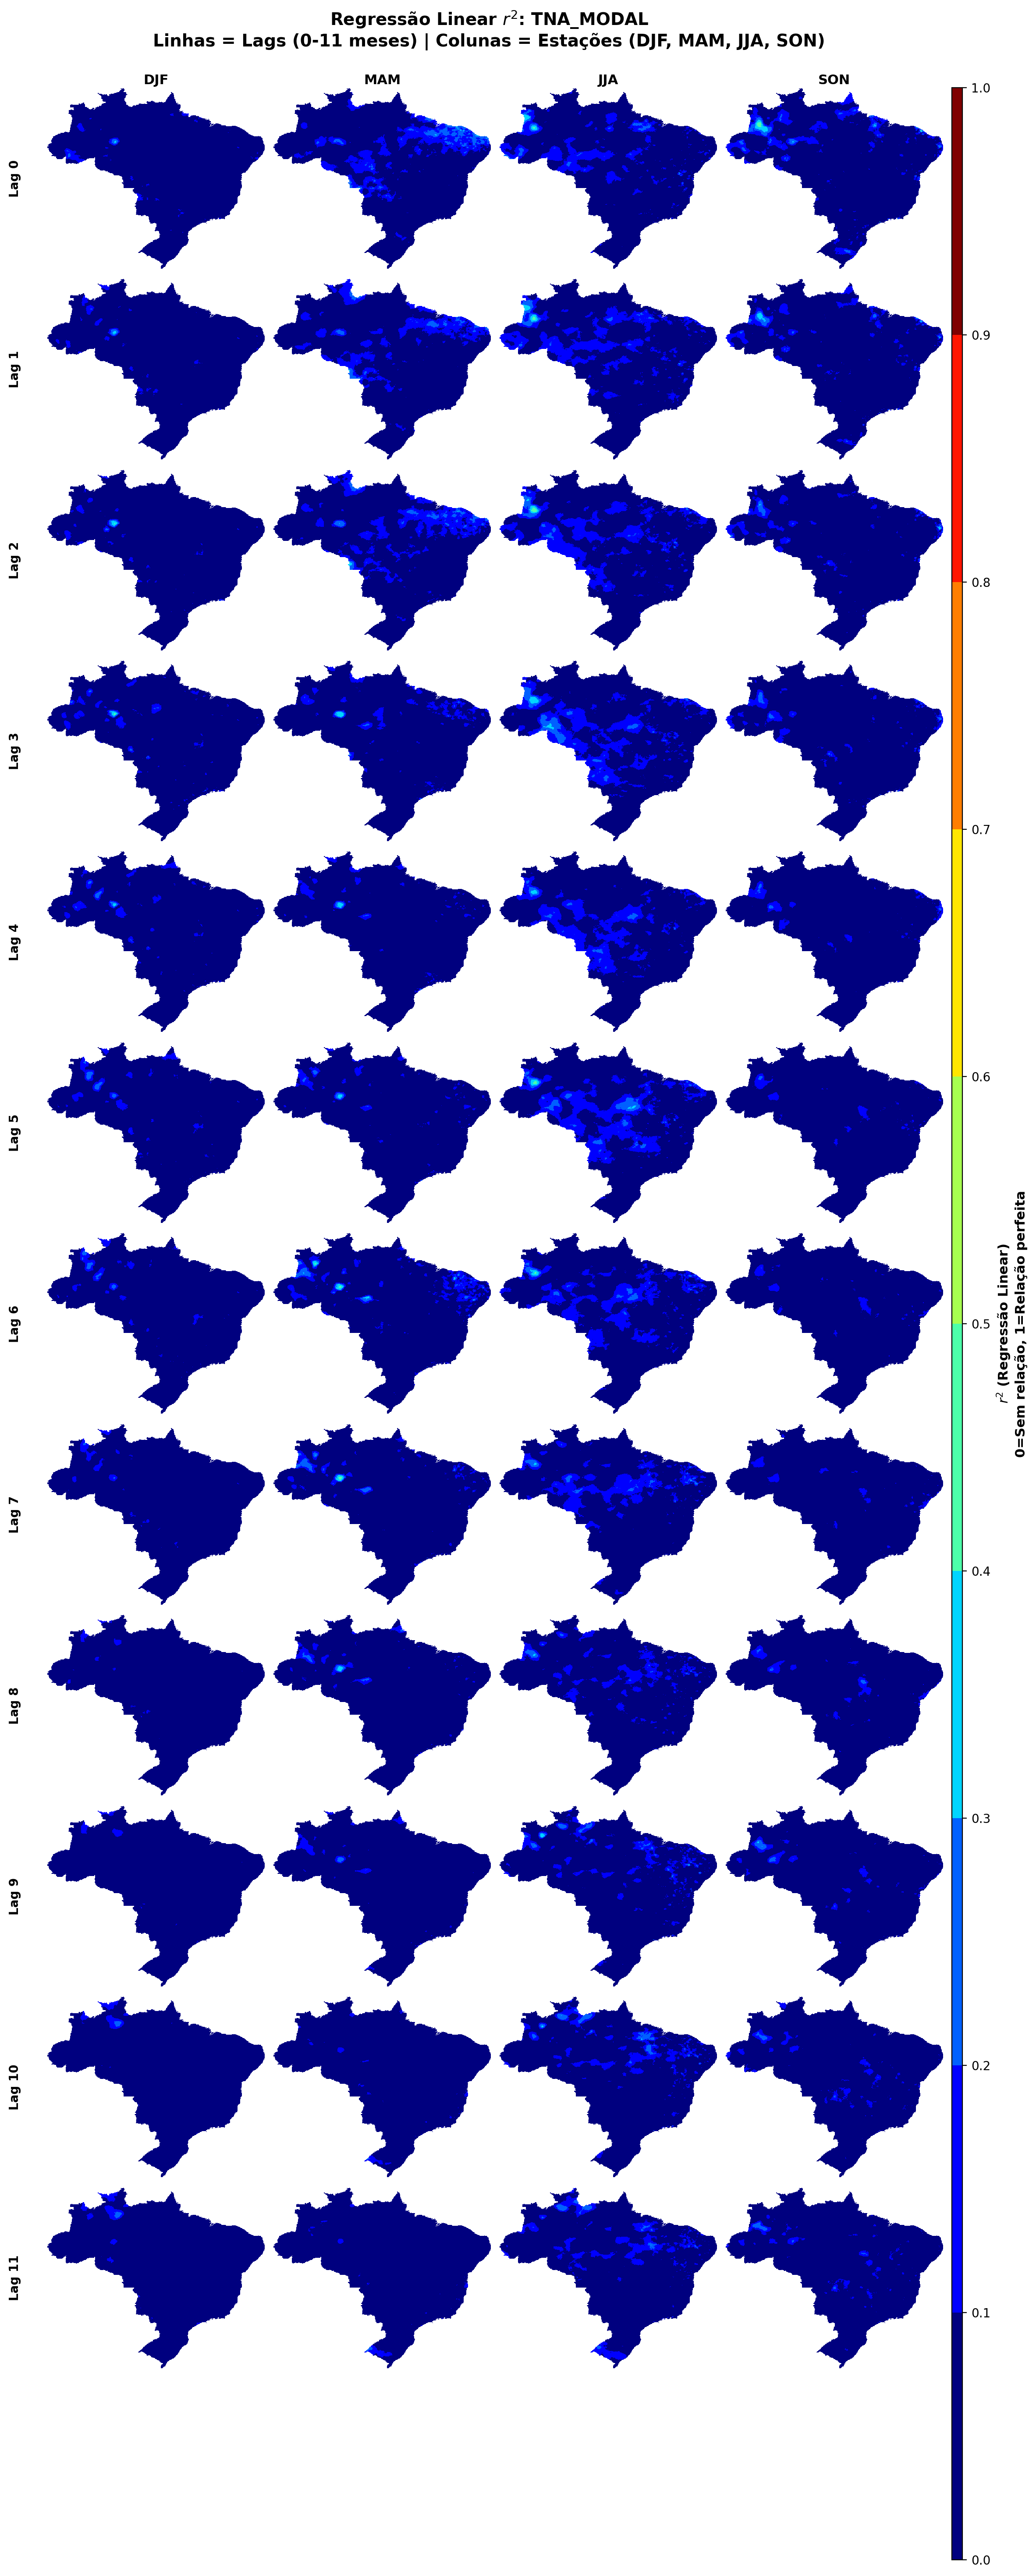

In [14]:
print("📊 Gerando plot 12x4 (Todos os Lags)...")
output_12x4 = plot_12x4_all_lags_r2(
    ds_combined,
    f'{mov_index}_MODAL',
    output_dir,
    seasons=seasons[:len(all_data)]
)

if output_12x4:
    print(f"✅ Plot salvo: {output_12x4}")
    from IPython.display import Image, display
    display(Image(filename=str(output_12x4)))
else:
    print("⚠️  Erro ao gerar plot 12x4")

## 7. Estatísticas dos Resultados

In [15]:
print("📊 ESTATÍSTICAS POR ESTAÇÃO\n" + "="*60)

for season_idx, season in enumerate(seasons[:len(all_data)]):
    print(f"\n{season}:")

    for lag in range(n_lags):
        data = ds_combined['regression_r2'].isel(mov=0, season=season_idx, lag=lag).values

        valid_points = np.sum(~np.isnan(data))

        if valid_points > 0:
            mean_r2 = np.nanmean(data)
            max_r2  = np.nanmax(data)
            min_r2  = np.nanmin(data)
            significant = np.sum(data > 0.1)

            print(f"  Lag {lag:2d}: {valid_points:4d} válidos | "
                  f"r² médio={mean_r2:.3f} | "
                  f"r² máx={max_r2:.3f} | "
                  f"r² mín={min_r2:.3f} | "
                  f">0.10: {significant:4d}")
        else:
            print(f"  Lag {lag:2d}: Sem dados válidos")

📊 ESTATÍSTICAS POR ESTAÇÃO

DJF:
  Lag  0: 71007 válidos | r² médio=0.016 | r² máx=0.335 | r² mín=0.000 | >0.10: 1448
  Lag  1: 71007 válidos | r² médio=0.017 | r² máx=0.354 | r² mín=0.000 | >0.10: 1585
  Lag  2: 71007 válidos | r² médio=0.018 | r² máx=0.413 | r² mín=0.000 | >0.10: 1454
  Lag  3: 71007 válidos | r² médio=0.024 | r² máx=0.431 | r² mín=0.000 | >0.10: 2809
  Lag  4: 71007 válidos | r² médio=0.021 | r² máx=0.365 | r² mín=0.000 | >0.10: 2768
  Lag  5: 71007 válidos | r² médio=0.022 | r² máx=0.286 | r² mín=0.000 | >0.10: 2870
  Lag  6: 71007 válidos | r² médio=0.021 | r² máx=0.264 | r² mín=0.000 | >0.10: 2400
  Lag  7: 71007 válidos | r² médio=0.016 | r² máx=0.219 | r² mín=0.000 | >0.10: 1368
  Lag  8: 71007 válidos | r² médio=0.012 | r² máx=0.173 | r² mín=0.000 | >0.10:  598
  Lag  9: 71007 válidos | r² médio=0.013 | r² máx=0.181 | r² mín=0.000 | >0.10:  637
  Lag 10: 71007 válidos | r² médio=0.015 | r² máx=0.270 | r² mín=0.000 | >0.10: 1192
  Lag 11: 71007 válidos | r² méd

## 8. Análise de Lags Ótimos

In [16]:
print("🎯 LAGS ÓTIMOS POR ESTAÇÃO\n" + "="*60)

for season_idx, season in enumerate(seasons[:len(all_data)]):
    r2_data = ds_combined['regression_r2'].isel(mov=0, season=season_idx).values

    mean_r2s = np.nanmean(r2_data, axis=(1, 2))
    optimal_lag = np.nanargmax(mean_r2s)
    optimal_r2  = mean_r2s[optimal_lag]

    max_r2s = np.nanmax(r2_data, axis=(1, 2))
    max_lag = np.nanargmax(max_r2s)
    max_r2  = max_r2s[max_lag]

    print(f"\n{season}:")
    print(f"  Lag ótimo (r² médio):  Lag {optimal_lag} (r²={optimal_r2:.3f})")
    print(f"  Lag ótimo (r² máximo): Lag {max_lag} (r²={max_r2:.3f})")

    top3_indices = np.argsort(mean_r2s)[-3:][::-1]
    print(f"  Top 3 lags (r² médio):")
    for rank, lag_idx in enumerate(top3_indices, 1):
        print(f"    {rank}º: Lag {lag_idx} (r²={mean_r2s[lag_idx]:.3f})")

🎯 LAGS ÓTIMOS POR ESTAÇÃO

DJF:
  Lag ótimo (r² médio):  Lag 3 (r²=0.024)
  Lag ótimo (r² máximo): Lag 3 (r²=0.431)
  Top 3 lags (r² médio):
    1º: Lag 3 (r²=0.024)
    2º: Lag 5 (r²=0.022)
    3º: Lag 4 (r²=0.021)

MAM:
  Lag ótimo (r² médio):  Lag 0 (r²=0.054)
  Lag ótimo (r² máximo): Lag 7 (r²=0.458)
  Top 3 lags (r² médio):
    1º: Lag 0 (r²=0.054)
    2º: Lag 2 (r²=0.052)
    3º: Lag 1 (r²=0.048)

JJA:
  Lag ótimo (r² médio):  Lag 3 (r²=0.067)
  Lag ótimo (r² máximo): Lag 2 (r²=0.469)
  Top 3 lags (r² médio):
    1º: Lag 3 (r²=0.067)
    2º: Lag 5 (r²=0.066)
    3º: Lag 2 (r²=0.062)

SON:
  Lag ótimo (r² médio):  Lag 0 (r²=0.043)
  Lag ótimo (r² máximo): Lag 0 (r²=0.490)
  Top 3 lags (r² médio):
    1º: Lag 0 (r²=0.043)
    2º: Lag 1 (r²=0.033)
    3º: Lag 2 (r²=0.029)


## 9. Salvar Dataset Combinado

In [17]:
combined_file = results_dir / f"{mov_index}_ALL_SEASONS_regression_combined.nc"
ds_combined.to_netcdf(combined_file)
print(f"💾 Dataset combinado salvo: {combined_file}")
print(f"   Tamanho: {combined_file.stat().st_size / 1024 / 1024:.2f} MB")

💾 Dataset combinado salvo: ../results/regression/TNA/TNA_ALL_SEASONS_regression_combined.nc
   Tamanho: 56.28 MB


## 10. Resumo Final

In [18]:
print("\n" + "="*60)
print("✅ VISUALIZAÇÃO CONCLUÍDA")
print("="*60)
print(f"\n📁 Arquivos gerados em: {output_dir}")
print(f"\n📊 Plots:")
if output_4x4:
    print(f"  - 4x4 (Lags Ótimos): {output_4x4.name}")
if output_12x4:
    print(f"  - 12x4 (Todos Lags): {output_12x4.name}")
print(f"\n💾 Dataset combinado: {combined_file.name}")
print(f"\n🎯 Análise: {mov_index} (Regressão Linear r²)")
print(f"   Estações: {', '.join(seasons[:len(all_data)])}")
print(f"   Lags: 0-{n_lags-1}")
print(f"   Grade: {len(lats)} lat × {len(lons)} lon")


✅ VISUALIZAÇÃO CONCLUÍDA

📁 Arquivos gerados em: ../results/regression/TNA/plots

📊 Plots:
  - 4x4 (Lags Ótimos): optimal_lag_seasons_TNA_MODAL_regression.png
  - 12x4 (Todos Lags): regression_12x4_grid_TNA_MODAL.png

💾 Dataset combinado: TNA_ALL_SEASONS_regression_combined.nc

🎯 Análise: TNA (Regressão Linear r²)
   Estações: DJF, MAM, JJA, SON
   Lags: 0-11
   Grade: 393 lat × 391 lon
